In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay,classification_report

In [3]:
#step 2. load breast cancer dataset

data=load_iris()
x=pd.DataFrame(data.data,columns=data.feature_names)
y=pd.Series(data.target) #0=malignant, 1=begin

In [5]:
print(f"shape of data:{x.shape}")
print(f"classes:{data.target_names}")
print(f"count of each class:\n{y.value_counts()}")


shape of data:(150, 4)
classes:['setosa' 'versicolor' 'virginica']
count of each class:
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
x.iloc[0:,0]

,sepal length (cm)
0,5.1
1,4.9
2,4.7
3,4.6
4,5.0
...,...
145,6.7
146,6.3
147,6.5
148,6.2


Text(0, 0.5, 'sepal width (cm)')

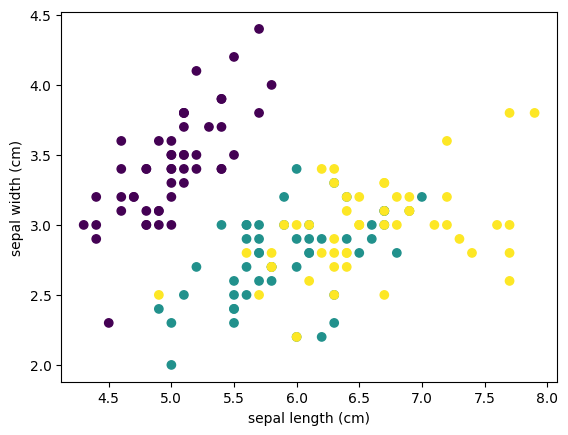

In [9]:
#visualize two features

plt.scatter(x.iloc[:,0],x.iloc[:,1],c=y)

plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])

In [10]:
#step 3. split into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
    )

In [11]:
#4. feature scaling


scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [12]:
#5. cretae and train svm model

model=SVC(kernel='linear')
model.fit(x_train,y_train)

SVC(kernel='linear')

In [13]:
#6. predict test data
y_pred=model.predict(x_test)

In [14]:
#7. evaluate the model
accuracy=accuracy_score(y_test,y_pred)
print(f"accuracy:{accuracy*100:.2f}%")

accuracy:100.00%


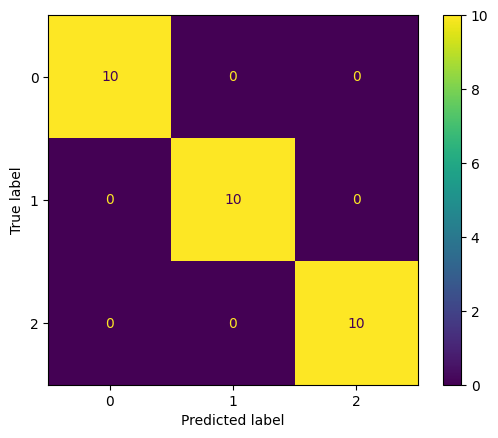

In [15]:
#8. display confusion matrix
cm=confusion_matrix(y_test,y_pred)
ConfusionMatrixDisplay(cm).plot()

In [16]:
#9. display classification report
print("classification report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names)
)

classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

